In [1]:
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score, f1_score, roc_auc_score, RocCurveDisplay, roc_curve, confusion_matrix,ConfusionMatrixDisplay
from pathlib import Path
import os
import sys

# Configure base directory for both Google Colab and local environments
if "google.colab" in sys.modules:
    drive_path = Path("/content/drive/MyDrive/pytorch-projects/pytorch-tabular-binary-classifier")
    if not drive_path.exists():
        from google.colab import drive
        drive.mount("/content/drive")

    if drive_path.exists():
        base = str(drive_path)
    else:
        repo_name = "pytorch-tabular-binary-classifier"
        if not Path(repo_name).exists():
            !git clone https://github.com/nfor-ojong/pytorch-tabular-binary-classifier.git
        base = repo_name
else:
    cwd = Path.cwd()
    base = str(cwd.parent if cwd.name == "notebooks" else cwd)

os.makedirs(f"{base}/artifacts", exist_ok=True)
os.makedirs(f"{base}/data/cleaned-data", exist_ok=True)
os.makedirs(f"{base}/evaluation-metrics", exist_ok=True)
os.makedirs(f"{base}/model", exist_ok=True)
os.makedirs(f"{base}/plots", exist_ok=True)

Mounted at /content/drive


In [2]:
# Load test data
test = pd.read_csv(base + "/data/cleaned-data/test_semi_processed.csv") # already processed

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Operating on {device}")

Operating on cpu


In [3]:
X_test = test.drop(columns=["TenYearCHD"])
y_test = test["TenYearCHD"]

# Convert to tensors
X_test_t = torch.tensor(X_test.to_numpy(), dtype=torch.float32) # convert to numpy array and then convert to tensor
y_test_t = torch.tensor(y_test.to_numpy(), dtype=torch.float32).reshape(-1, 1) # make target 2-dimensional to meet model specifications

# Move test tensors to device
X_test_t = X_test_t.to(device)
y_test_t = y_test_t.to(device)

# Display tensor shapes
print("X_test_t shape: ", X_test_t.shape)
print("y_test_t shape: ", y_test_t.shape)

X_test_t shape:  torch.Size([848, 18])
y_test_t shape:  torch.Size([848, 1])


In [4]:
# Construct neuaral network exactly as it was done during training
model = nn.Sequential(
    nn.Linear(X_test_t.shape[1], 64),
    nn.LeakyReLU(0.1),      # Prevents dying ReLUs completely
    nn.Dropout(0.4),        # Gentle regularization (not 0.6!)

    nn.Linear(64, 32),
    nn.LeakyReLU(0.1),
    nn.Dropout(0.8),

    nn.Linear(32, 1)
)
# Load saved model parameters
model.load_state_dict(torch.load(base + "/model/neural_network.pth", weights_only=True))
# Move model to device
model = model.to(device)


In [5]:
# Put model in evaluation mode do predictions
model.eval()
with torch.no_grad(): # Disable gradient calculations in this block
  preds_test = model(X_test_t)
  probs = torch.sigmoid(preds_test) # convert unbounded logits to probabilities by appling sigmoid function

  # Load and use stored best threshold
  best_threshold = float(Path(base + "/model/threshold.txt").read_text())
  y_preds = probs > best_threshold # predict class 1 anything above the threshold and class 0 otherwise

PERFORMANCE METRICS ON TEST SET
ROC AUC (test): 68.83%
Recall score (test): 40.31%
F1 score (test): 31.61%


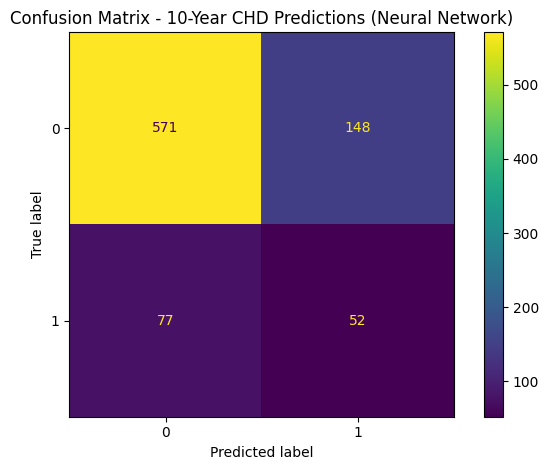

In [6]:
# Evaluate model
auc_roc = roc_auc_score(y_test_t, probs) # area under the ROC curve
recall = recall_score(y_test_t, y_preds)
f1 = f1_score(y_test_t, y_preds)

# Display metrics
print("PERFORMANCE METRICS ON TEST SET")
print("================================")
print("ROC AUC (test): {:.2f}%".format(100*auc_roc))
print("Recall score (test): {:.2f}%".format(100*recall))
print("F1 score (test): {:.2f}%".format(100*f1))

# Find and display confusion matrix
cm = confusion_matrix(y_test_t, y_preds)
disp = ConfusionMatrixDisplay(cm)
disp.plot()
plt.title("Confusion Matrix - 10-Year CHD Predictions (Neural Network)")
plt.tight_layout()
plt.savefig(base + "/plots/confusion_matrix_test.png")
plt.show()

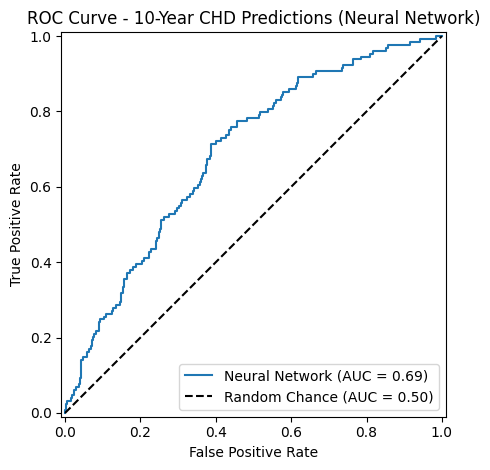

In [7]:
# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_test_t, probs)
RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc_roc, estimator_name="Neural Network").plot()
plt.plot([0, 1], [0, 1], "k--", label="Random Chance (AUC = 0.50)")  # diagonal line showing random chance
plt.legend()
plt.title("ROC Curve - 10-Year CHD Predictions (Neural Network)")
plt.tight_layout()
plt.savefig(base + "/plots/roc_curve_test.png")
plt.show()